In [3]:
import csv

file_path = "../../datasets/heart.csv"

with open(file_path, "r", newline="") as file:
    data = list(csv.reader(file))

headers = data[0]
rows = data[1:]

print("Total rows:", len(rows))
print("Total columns:", len(headers))
print("Columns:", headers)

Total rows: 1025
Total columns: 14
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [4]:
unique_rows = []
duplicate_rows = []

for row in rows:
    if row in unique_rows:
        duplicate_rows.append(row)
    else:
        unique_rows.append(row)

print("Original rows:", len(rows))
print("Unique rows:", len(unique_rows))
print("Duplicate rows:", len(duplicate_rows))

for row in duplicate_rows[:5]:
    print(row)

Original rows: 1025
Unique rows: 302
Duplicate rows: 723
['34', '0', '1', '118', '210', '0', '1', '192', '0', '0.7', '2', '0', '2', '1']
['50', '0', '1', '120', '244', '0', '1', '162', '0', '1.1', '2', '0', '2', '1']
['46', '1', '0', '120', '249', '0', '0', '144', '0', '0.8', '2', '0', '3', '0']
['55', '1', '0', '140', '217', '0', '1', '111', '1', '5.6', '0', '0', '3', '0']
['66', '0', '2', '146', '278', '0', '0', '152', '0', '0', '1', '1', '2', '1']


In [5]:
if len(rows) > 0:
    duplicate_percentage = len(duplicate_rows) / len(rows) * 100
else:
    duplicate_percentage = 0

print(f"Duplicate percentage: {duplicate_percentage:.2f}%")

Duplicate percentage: 70.54%


In [6]:
clean_rows = unique_rows

remaining_duplicates = []

for i in range(len(clean_rows)):
    for j in range(i + 1, len(clean_rows)):
        if clean_rows[i] == clean_rows[j]:
            remaining_duplicates.append(clean_rows[i])

print("Rows before cleaning:", len(rows))
print("Rows after cleaning:", len(clean_rows))
print("Rows removed:", len(rows) - len(clean_rows))
print("Remaining duplicates:", len(remaining_duplicates))

Rows before cleaning: 1025
Rows after cleaning: 302
Rows removed: 723
Remaining duplicates: 0


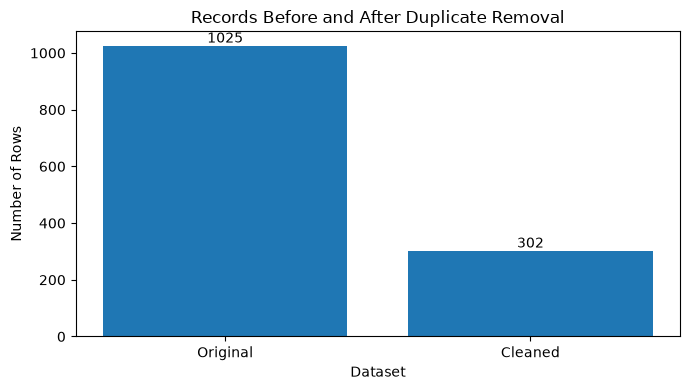

Cleaned dataset saved: ../../datasets/heart_cleaned.csv


In [7]:
import matplotlib.pyplot as plt

output_path = "../../datasets/heart_cleaned.csv"

with open(output_path, "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(headers)
    writer.writerows(clean_rows)

labels = ["Original", "Cleaned"]
counts = [len(rows), len(clean_rows)]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, counts)

plt.title("Records Before and After Duplicate Removal")
plt.xlabel("Dataset")
plt.ylabel("Number of Rows")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("Cleaned dataset saved:", output_path)

In [8]:
print("TASK 4: FINAL SUMMARY")
print("-" * 30)

print("Original records:", len(rows))
print("Duplicates detected:", len(duplicate_rows))
print("Records removed:", len(rows) - len(clean_rows))
print("Cleaned records:", len(clean_rows))
print("Remaining duplicates:", len(remaining_duplicates))

if len(remaining_duplicates) == 0:
    print("Verification successful!")
else:
    print("Duplicates still exist!")

TASK 4: FINAL SUMMARY
------------------------------
Original records: 1025
Duplicates detected: 723
Records removed: 723
Cleaned records: 302
Remaining duplicates: 0
Verification successful!


# Task 4: Duplicate Rows Detection and Removal

## Objective
To identify and remove exact duplicate rows from the Heart Disease dataset using a custom comparison algorithm without built-in duplicate detection functions.

## Methodology
1. Loaded the dataset using Python's CSV module.
2. Compared each row with previously identified unique rows.
3. Calculated the number and percentage of duplicate records.
4. Removed duplicate rows while preserving the first occurrence.
5. Verified the cleaned dataset and saved it separately.
6. Visualized the record counts before and after cleaning.

## Impact on Data Integrity
Duplicate records can distort statistical summaries and affect the distribution of data. They may also lead to misleading machine learning evaluation if identical records appear in both training and testing datasets.

However, identical measurements do not always mean that two records belong to the same patient. Duplicate removal should be performed carefully.

## Impact on Model Performance
Duplicates can influence model training and may cause overly optimistic evaluation results when similar records occur in both training and testing sets. Removing duplicates does not guarantee higher accuracy; the impact depends on the dataset and evaluation method.

## Conclusion
A custom algorithm was used to detect exact duplicate rows, remove repeated records, verify the cleaned dataset, and visualize the results. The original dataset was preserved, and the cleaned dataset was saved separately.

**Results:** Refer to the notebook outputs for the actual number of duplicates detected and records removed.
